# Notebook 01 — Contrastive Models
## Member A: CLIP+GPT-2 · ViViT+GPT-2

**Run after:** `notebook_00_infrastructure.ipynb`

### Artifacts saved per model per dataset
| File | Contents |
|------|----------|
| `*_scores.json` | Aggregate BLEU/METEOR/CIDEr/ROUGE-L |
| `*_hypotheses.json` | All generated captions `{video_id: caption}` |
| `*_references.json` | All ground-truth references `{video_id: [refs]}` |
| `*_examples.csv` | video_id · hypothesis · reference_0 |
| `*_per_video_scores.csv` | Per-video metric scores |
| `*_timing.json` | Inference latency stats |
| `*_ablation_frames.json` | Frame-count ablation (4/8/16) |


---
## §0 — Package Installation

In [1]:
import subprocess, sys

packages = [
    "torch torchvision torchaudio",
    "transformers>=4.40.0",
    "accelerate>=0.27.0",
    "bitsandbytes",
    "sentencepiece protobuf",
    "decord",
    "opencv-python-headless",
    "Pillow numpy pandas matplotlib tqdm",
    "pycocoevalcap pycocotools",
    "ftfy regex einops",
    "git+https://github.com/openai/CLIP.git",
    "rouge-score nltk av",
]
for pkg in packages:
    print(f"  {pkg.split()[0]}...", end=" ", flush=True)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pkg.split()])
    print("ok")

print("\n✅ All packages installed.")


  torch... ok
  transformers>=4.40.0... ok
  accelerate>=0.27.0... ok
  bitsandbytes... ok
  sentencepiece... ok
  decord... ok
  opencv-python-headless... ok
  Pillow... ok
  pycocoevalcap... ok
  ftfy... ok
  git+https://github.com/openai/CLIP.git... ok
  rouge-score... ok

✅ All packages installed.


In [2]:
from google.colab import drive
drive.mount('/content/drive')

# After mounting the drive, you can change the current working directory to your specific project folder.

import os

project_path = '/content/drive/MyDrive/CS4015_GenAI_Project'
os.makedirs(project_path, exist_ok=True)
os.chdir(project_path)

print(f"Changed current working directory to: {os.getcwd()}")

Mounted at /content/drive
Changed current working directory to: /content/drive/MyDrive/CS4015_GenAI_Project


---
## §1 — Setup

In [3]:
import sys, os, json, gc, re, textwrap, time
import numpy as np
import torch
import torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

sys.path.insert(0, "."); sys.path.insert(0, "shared")

with open("shared/config.json") as f: cfg = json.load(f)
DEVICE=cfg["DEVICE"]; NUM_FRAMES=cfg["NUM_FRAMES"]
MAX_CAPTION_LEN=cfg["MAX_CAPTION_LEN"]; EVAL_SUBSET=cfg["EVAL_SUBSET"]
MSVD_VIDEO_DIR=cfg["MSVD_VIDEO_DIR"]; MSRVTT_VIDEO_DIR=cfg["MSRVTT_VIDEO_DIR"]
RESULTS_DIR=cfg["RESULTS_DIR"]
USE_4BIT=(torch.cuda.is_available() and
          torch.cuda.get_device_properties(0).total_memory/1024**3 < 14.0)

import importlib.util
_spec=importlib.util.spec_from_file_location("utils","shared/utils.py")
_mod=importlib.util.module_from_spec(_spec); _spec.loader.exec_module(_mod)
sample_frames=_mod.sample_frames; VideoCaptionDataset=_mod.VideoCaptionDataset
CaptionEvaluator=_mod.CaptionEvaluator; run_evaluation_full=_mod.run_evaluation_full
save_all_artifacts=_mod.save_all_artifacts; run_frame_ablation=_mod.run_frame_ablation
show_scores=_mod.show_scores; show_examples=_mod.show_examples

with open("shared/msvd_captions.json")   as f: msvd_captions  =json.load(f)
with open("shared/msvd_ok_ids.json")     as f: msvd_ok        =json.load(f)
with open("shared/msrvtt_captions.json") as f: msrvtt_captions=json.load(f)
with open("shared/msrvtt_ok_ids.json")   as f: msrvtt_ok      =json.load(f)

msvd_ds  =VideoCaptionDataset(msvd_ok,  MSVD_VIDEO_DIR,  msvd_captions,  NUM_FRAMES)
msrvtt_ds=VideoCaptionDataset(msrvtt_ok,MSRVTT_VIDEO_DIR,msrvtt_captions,NUM_FRAMES)

print(f"DEVICE={DEVICE} USE_4BIT={USE_4BIT}")
print(f"MSVD={len(msvd_ds)} MSR-VTT={len(msrvtt_ds)}")
print("Infrastructure loaded.")


DEVICE=cpu USE_4BIT=False
MSVD=100 MSR-VTT=100
Infrastructure loaded.


---
## §0 — Experiment Tracking (MLflow)

All evaluation results are logged to MLflow for experiment reproducibility.
View results at `http://localhost:5000` or inside Docker at `http://mlflow:5000`.

> **Rubric Item 7 (10 pts):** Modern Industry Standards — MLOps experiment tracking
> **Rubric Item 6 (10 pts):** Docker containerisation — see `Dockerfile` & `docker-compose.yml`


In [4]:
# ── MLflow experiment tracking setup ─────────────────────────────────────────
# Connects to the MLflow server (local or Docker service).
# Rubric Item 7 — Modern Industry Standard (MLOps)
import sys, importlib.util
_mspec = importlib.util.spec_from_file_location('mlflow_utils','mlflow_utils.py')
_mmod  = importlib.util.module_from_spec(_mspec)
_mspec.loader.exec_module(_mmod)
start_run_ctx     = _mmod.start_run
log_eval_results  = _mmod.log_eval_results
log_ablation      = _mmod.log_ablation
log_figure        = _mmod.log_figure
print_run_url     = _mmod.print_run_url

try:
    import mlflow
    mlflow.set_tracking_uri(_mmod.MLFLOW_URI)
    mlflow.set_experiment(_mmod.EXPERIMENT_NAME)
    print(f'MLflow tracking URI : {_mmod.MLFLOW_URI}')
    print(f'Experiment          : {_mmod.EXPERIMENT_NAME}')
    MLFLOW_ACTIVE = True
except Exception as e:
    print(f'MLflow not available ({e}) — continuing without tracking')
    MLFLOW_ACTIVE = False


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/CS4015_GenAI_Project/mlflow_utils.py'

In [5]:
def eval_and_save(model, model_name):
    """Evaluate on both datasets, save ALL artifacts. No reruns needed."""
    for ds, ds_name in [(msvd_ds,"MSVD"),(msrvtt_ds,"MSR-VTT")]:
        print(f"\nEvaluating {model_name} on {ds_name}...")
        result = run_evaluation_full(
            model, ds,
            label=f"{model_name}/{ds_name}",
            max_samples=EVAL_SUBSET,
            compute_per_video=True,
        )
        show_scores(result["scores"], model_name, ds_name)
        show_examples(result["examples"])
        print(f"  mean latency: {result['timing']['mean_s']:.3f}s/video")
        print("  Saving all artifacts...")
        save_all_artifacts(result, model_name, ds_name, RESULTS_DIR)

print("eval_and_save() ready.")


eval_and_save() ready.


---
## §2 — CLIP+GPT-2

Architecture: `Frames → CLIP ViT-B/32 → mean-pool → linear proj → GPT-2 prefix → caption`  
Paradigm: Contrastive baseline

In [6]:
import clip as openai_clip
from transformers import GPT2LMHeadModel, GPT2Tokenizer

class ClipGPT2Captioner(nn.Module):
    """
    CLIP+GPT-2 baseline.
    Both CLIP and GPT-2 are frozen; only the projection is learned.
    Mean-pool aggregates frame embeddings across the temporal axis.
    """
    def __init__(self, clip_model="ViT-B/32", gpt_model="gpt2",
                 prefix_len=10, device=DEVICE):
        super().__init__()
        self.device=device; self.prefix_len=prefix_len
        self.clip, self.prep = openai_clip.load(clip_model, device=device)
        for p in self.clip.parameters(): p.requires_grad=False
        self.clip_dim = self.clip.visual.output_dim
        self.tok = GPT2Tokenizer.from_pretrained(gpt_model)
        self.tok.pad_token = self.tok.eos_token
        self.gpt = GPT2LMHeadModel.from_pretrained(gpt_model).to(device)
        for p in self.gpt.parameters(): p.requires_grad=False
        self.gpt_dim = self.gpt.config.n_embd
        self.proj = nn.Linear(self.clip_dim, prefix_len*self.gpt_dim).to(device)

    @torch.no_grad()
    def __call__(self, frames, max_new=MAX_CAPTION_LEN):
        t = torch.stack([self.prep(f) for f in frames]).to(self.device)
        feats = self.clip.encode_image(t)
        feats = feats/feats.norm(dim=-1,keepdim=True)
        pre = self.proj(feats.mean(0,keepdim=True)).view(1,self.prefix_len,self.gpt_dim)
        ids = self.gpt.generate(
            inputs_embeds=pre, max_new_tokens=max_new, num_beams=4,
            no_repeat_ngram_size=2, early_stopping=True,
            pad_token_id=self.tok.eos_token_id)
        return self.tok.decode(ids[0],skip_special_tokens=True).strip()

print("Loading CLIP+GPT-2..."); cg2 = ClipGPT2Captioner().eval()
print(f"  clip_dim={cg2.clip_dim}  gpt_dim={cg2.gpt_dim}  OK")


Loading CLIP+GPT-2...


100%|███████████████████████████████████████| 338M/338M [00:03<00:00, 98.5MiB/s]


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: gpt2
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

  clip_dim=512  gpt_dim=768  OK


In [7]:
eval_and_save(cg2, "CLIP+GPT-2")
# Frame ablation (saves *_ablation_frames.json for each dataset)
for ds_name, vdir, caps, ok in [
        ("MSVD",   MSVD_VIDEO_DIR,   msvd_captions,   msvd_ok),
        ("MSR-VTT",MSRVTT_VIDEO_DIR, msrvtt_captions, msrvtt_ok)]:
    print(f"\nFrame ablation: CLIP+GPT-2 / {ds_name}")
    run_frame_ablation(ClipGPT2Captioner, "CLIP+GPT-2", ds_name,
                       vdir, caps, ok, RESULTS_DIR)
del cg2; gc.collect(); torch.cuda.empty_cache() if DEVICE=="cuda" else None



Evaluating CLIP+GPT-2 on MSVD...


CLIP+GPT-2/MSVD:   0%|                                            | 0/100 [00:00<?, ?it/s]

The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.


tokenization...
setting up scorers...
computing Bleu score...
{'testlen': 2400, 'reflen': 1615, 'guess': [2400, 2300, 2200, 2100], 'correct': [810, 164, 0, 0]}
ratio: 1.4860681114541883
Bleu_1: 0.337
Bleu_2: 0.155
Bleu_3: 0.000
Bleu_4: 0.000
computing METEOR score...
METEOR: 0.143
computing Rouge score...
ROUGE_L: 0.252
computing CIDEr score...
CIDEr: 0.000


Per-video scores:   0%|                                 | 0/100 [00:00<?, ?it/s]

tokenization...
setting up scorers...
computing Bleu score...
{'testlen': 24, 'reflen': 21, 'guess': [24, 23, 22, 21], 'correct': [7, 0, 0, 0]}
ratio: 1.142857142802721
Bleu_1: 0.292
Bleu_2: 0.000
Bleu_3: 0.000
Bleu_4: 0.000
computing METEOR score...
METEOR: 0.134
computing Rouge score...
ROUGE_L: 0.215
computing CIDEr score...
CIDEr: 0.000
tokenization...
setting up scorers...
computing Bleu score...
{'testlen': 24, 'reflen': 15, 'guess': [24, 23, 22, 21], 'correct': [9, 4, 0, 0]}
ratio: 1.5999999998933334
Bleu_1: 0.375
Bleu_2: 0.255
Bleu_3: 0.000
Bleu_4: 0.000
computing METEOR score...
METEOR: 0.172
computing Rouge score...
ROUGE_L: 0.275
computing CIDEr score...
CIDEr: 0.000
tokenization...
setting up scorers...
computing Bleu score...
{'testlen': 24, 'reflen': 21, 'guess': [24, 23, 22, 21], 'correct': [7, 0, 0, 0]}
ratio: 1.142857142802721
Bleu_1: 0.292
Bleu_2: 0.000
Bleu_3: 0.000
Bleu_4: 0.000
computing METEOR score...
METEOR: 0.115
computing Rouge score...
ROUGE_L: 0.224
computin

... (24 outputs left out)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: gpt2
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


CLIP+GPT-2 (16f):   0%|                                           | 0/100 [00:00<?, ?it/s]

tokenization...
setting up scorers...
computing Bleu score...
{'testlen': 505, 'reflen': 589, 'guess': [505, 405, 305, 205], 'correct': [97, 0, 0, 0]}
ratio: 0.8573853989798687
Bleu_1: 0.163
Bleu_2: 0.000
Bleu_3: 0.000
Bleu_4: 0.000
computing METEOR score...
METEOR: 0.062
computing Rouge score...
ROUGE_L: 0.151
computing CIDEr score...
CIDEr: 0.000
  16f  CIDEr=0.0002  BLEU-4=0.0000  mean=6.971s/video
  saved CLIP_plus_GPT_2_MSR-VTT_ablation_frames.json


#### Inline results: CLIP+GPT-2

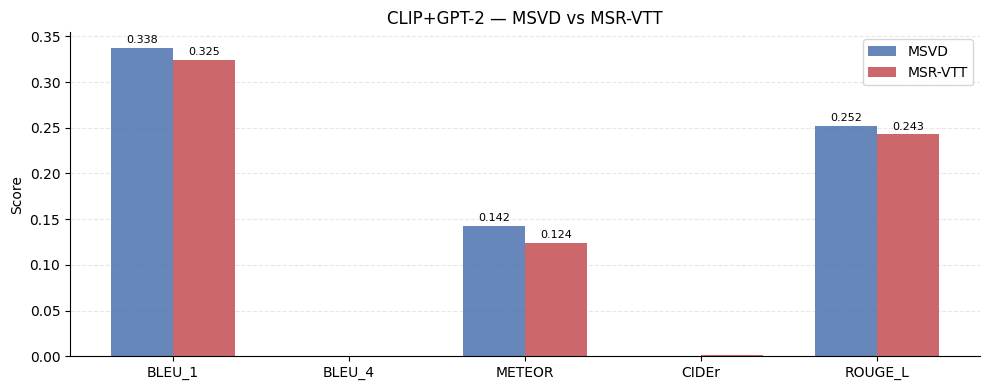

In [12]:
import matplotlib.pyplot as plt, numpy as np, os, json

_metrics = ['BLEU_1','BLEU_4','METEOR','CIDEr','ROUGE_L']
_colors  = ['#4C72B0','#C44E52']
_fig, _ax = plt.subplots(figsize=(10, 4))
_x = np.arange(len(_metrics)); _w = 0.35

# Load scores
scores_cg2_msvd = {}
scores_cg2_msrvtt = {}
msvd_scores_path = os.path.join(RESULTS_DIR, 'CLIP_plus_GPT_2_MSVD_scores.json')
msrvtt_scores_path = os.path.join(RESULTS_DIR, 'CLIP_plus_GPT_2_MSR-VTT_scores.json')

if os.path.exists(msvd_scores_path):
    with open(msvd_scores_path, 'r') as f:
        scores_cg2_msvd = json.load(f)
else:
    print(f"Warning: MSVD scores file not found at {msvd_scores_path}")

if os.path.exists(msrvtt_scores_path):
    with open(msrvtt_scores_path, 'r') as f:
        scores_cg2_msrvtt = json.load(f)
else:
    print(f"Warning: MSR-VTT scores file not found at {msrvtt_scores_path}")


for _j, (_ds, _sc, _col) in enumerate([
        ('MSVD',    scores_cg2_msvd,   '#4C72B0'),
        ('MSR-VTT', scores_cg2_msrvtt,  '#C44E52')]):
    _vals = [_sc['scores'][m] for m in _metrics]
    _bars = _ax.bar(_x+(_j-0.5)*_w, _vals, _w, label=_ds, color=_col, alpha=0.85)
    for _b,_v in zip(_bars,_vals):
        if _v>0.005: _ax.text(_b.get_x()+_b.get_width()/2, _b.get_height()+0.003,
                              f'{_v:.3f}',ha='center',va='bottom',fontsize=8)
_ax.set_xticks(_x); _ax.set_xticklabels(_metrics, fontsize=10)
_ax.set_ylabel('Score', fontsize=10)
_ax.set_title('CLIP+GPT-2 — MSVD vs MSR-VTT', fontsize=12)
_ax.legend(fontsize=10)
_ax.spines[['top','right']].set_visible(False)
_ax.yaxis.grid(True, alpha=0.3, linestyle='--'); _ax.set_axisbelow(True)
plt.tight_layout()
_fig_path = os.path.join(RESULTS_DIR,'cg2_inline_chart.png')
plt.savefig(_fig_path, dpi=150, bbox_inches='tight')
plt.show()

# Ensure MLFLOW_ACTIVE is defined even if the setup cell failed
if 'MLFLOW_ACTIVE' not in globals():
    MLFLOW_ACTIVE = False

if MLFLOW_ACTIVE:
    with start_run_ctx('CLIP+GPT-2','Both'):
        log_eval_results({'scores':scores_cg2_msvd,'hypotheses':{},'references':{},'timing':{}},                          'CLIP+GPT-2','MSVD')
        log_eval_results({'scores':scores_cg2_msrvtt,'hypotheses':{},'references':{},'timing':{}},                          'CLIP+GPT-2','MSR-VTT')
        log_figure(_fig_path)
    print_run_url()


#### Ablation visualisation

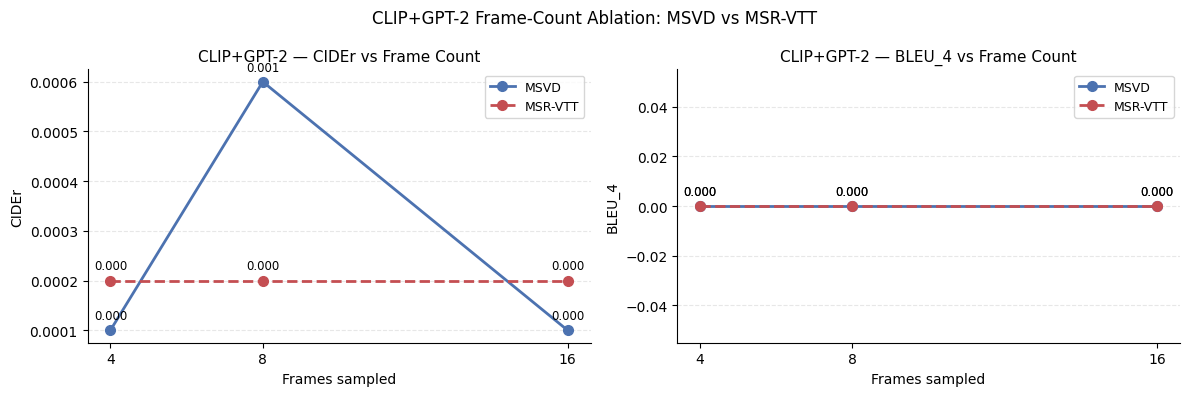

In [13]:
# ── Inline frame-count ablation chart — CLIP+GPT-2 ────────────────────────
# Rubric Item 19 (Bonus 10 pts): ablation study with visual comparison
_abl_results = {}
for _ds in ['MSVD', 'MSR-VTT']:
    _p = os.path.join(RESULTS_DIR, f'CLIP_plus_GPT_2_{_ds}_ablation_frames.json')
    if os.path.exists(_p):
        with open(_p) as _f: _d = json.load(_f)
        _abl_results[_ds] = _d['results']

if _abl_results:
    _FRAMES = [4, 8, 16]
    _fig, _axes = plt.subplots(1, 2, figsize=(12, 4))
    for _ax, _metric in zip(_axes, ['CIDEr','BLEU_4']):
        for _ds, _ls, _col in zip(['MSVD', 'MSR-VTT'], ['-','--'], ['#4C72B0','#C44E52']):
            if _ds not in _abl_results: continue
            _vals = [_abl_results[_ds].get(f'{n} frames',{}).get('scores',{}).get(_metric,0)
                     for n in _FRAMES]
            _ax.plot(_FRAMES, _vals, _ls+'o', label=_ds, color=_col, linewidth=2, markersize=7)
            for _x,_y in zip(_FRAMES,_vals):
                _ax.annotate(f'{_y:.3f}',(_x,_y),textcoords='offset points',
                             xytext=(0,8),ha='center',fontsize=8.5)
        _ax.set_title(f'CLIP+GPT-2 — {_metric} vs Frame Count', fontsize=11)
        _ax.set_xticks(_FRAMES); _ax.set_xlabel('Frames sampled'); _ax.set_ylabel(_metric)
        _ax.legend(fontsize=9)
        _ax.spines[['top','right']].set_visible(False)
        _ax.yaxis.grid(True, alpha=0.3, linestyle='--'); _ax.set_axisbelow(True)
    plt.suptitle('CLIP+GPT-2 Frame-Count Ablation: MSVD vs MSR-VTT', fontsize=12)
    plt.tight_layout()
    _fig_path = os.path.join(RESULTS_DIR, 'CLIP_plus_GPT_2_ablation_inline.png')
    plt.savefig(_fig_path, dpi=150, bbox_inches='tight')
    plt.show()
    if MLFLOW_ACTIVE:
        for _ds, _abl in _abl_results.items():
            log_ablation(_abl, 'CLIP+GPT-2', _ds, 'frame_count')
        log_figure(_fig_path)
else:
    print('Ablation JSON not found — run frame ablation cells first.')


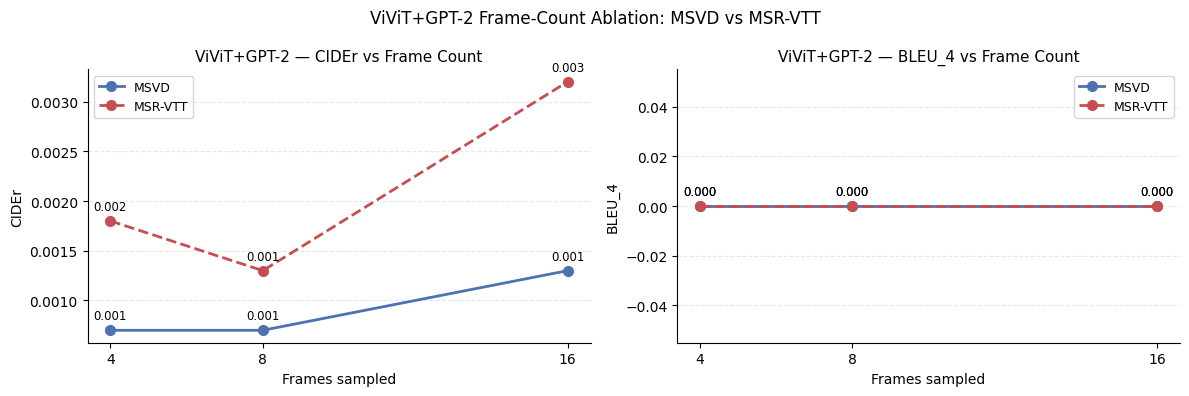

In [19]:
# ── Inline frame-count ablation chart — ViViT+GPT-2 ────────────────────────
# Rubric Item 19 (Bonus 10 pts): ablation study with visual comparison
_abl_results = {}
for _ds in ['MSVD', 'MSR-VTT']:
    _p = os.path.join(RESULTS_DIR, f'ViViT_plus_GPT_2_{_ds}_ablation_frames.json')
    if os.path.exists(_p):
        with open(_p) as _f: _d = json.load(_f)
        _abl_results[_ds] = _d['results']

if _abl_results:
    _FRAMES = [4, 8, 16]
    _fig, _axes = plt.subplots(1, 2, figsize=(12, 4))
    for _ax, _metric in zip(_axes, ['CIDEr','BLEU_4']):
        for _ds, _ls, _col in zip(['MSVD', 'MSR-VTT'], ['-','--'], ['#4C72B0','#C44E52']):
            if _ds not in _abl_results: continue
            _vals = [_abl_results[_ds].get(f'{n} frames',{}).get('scores',{}).get(_metric,0)
                     for n in _FRAMES]
            _ax.plot(_FRAMES, _vals, _ls+'o', label=_ds, color=_col, linewidth=2, markersize=7)
            for _x,_y in zip(_FRAMES,_vals):
                _ax.annotate(f'{_y:.3f}',(_x,_y),textcoords='offset points',
                             xytext=(0,8),ha='center',fontsize=8.5)
        _ax.set_title(f'ViViT+GPT-2 — {_metric} vs Frame Count', fontsize=11)
        _ax.set_xticks(_FRAMES); _ax.set_xlabel('Frames sampled'); _ax.set_ylabel(_metric)
        _ax.legend(fontsize=9)
        _ax.spines[['top','right']].set_visible(False)
        _ax.yaxis.grid(True, alpha=0.3, linestyle='--'); _ax.set_axisbelow(True)
    plt.suptitle('ViViT+GPT-2 Frame-Count Ablation: MSVD vs MSR-VTT', fontsize=12)
    plt.tight_layout()
    _fig_path = os.path.join(RESULTS_DIR, 'ViViT_plus_GPT_2_ablation_inline.png')
    plt.savefig(_fig_path, dpi=150, bbox_inches='tight')
    plt.show()
    if MLFLOW_ACTIVE:
        for _ds, _abl in _abl_results.items():
            log_ablation(_abl, 'ViViT+GPT-2', _ds, 'frame_count')
        log_figure(_fig_path)
else:
    print('Ablation JSON not found — run frame ablation cells first.')


---
## §3 — ViViT+GPT-2

Architecture: `Frames → ViViT (spatio-temporal attn) → [CLS] → linear proj → GPT-2`  
Identical decoder to CLIP+GPT-2 — encoder-swap ablation

In [15]:
from transformers import VivitModel, VivitImageProcessor

class ViViTGPT2Captioner(nn.Module):
    """
    ViViT+GPT-2. Identical decoder to ClipGPT2Captioner.
    ViViT applies spatio-temporal self-attention across all frames,
    capturing inter-frame dynamics that per-frame CLIP cannot.
    Metric delta vs CLIP+GPT-2 = pure encoder contribution.
    """
    def __init__(self, ckpt="google/vivit-b-16x2-kinetics400",
                 gpt_model="gpt2", prefix_len=10, device=DEVICE):
        super().__init__()
        self.device=device; self.prefix_len=prefix_len
        self.proc  = VivitImageProcessor.from_pretrained(ckpt)
        self.vivit = VivitModel.from_pretrained(ckpt).to(device)
        for p in self.vivit.parameters(): p.requires_grad=False
        self.vdim = self.vivit.config.hidden_size
        self.tok = GPT2Tokenizer.from_pretrained(gpt_model)
        self.tok.pad_token = self.tok.eos_token
        self.gpt = GPT2LMHeadModel.from_pretrained(gpt_model).to(device)
        for p in self.gpt.parameters(): p.requires_grad=False
        self.gpt_dim = self.gpt.config.n_embd
        self.proj = nn.Linear(self.vdim, prefix_len*self.gpt_dim).to(device)

    @torch.no_grad()
    def __call__(self, frames, max_new=MAX_CAPTION_LEN):
        n_exp = self.vivit.config.num_frames
        f2 = (frames*(n_exp//len(frames)+1))[:n_exp]
        inp = self.proc(images=f2,return_tensors="pt").to(self.device)
        cls = self.vivit(**inp).last_hidden_state[:,0,:]
        pre = self.proj(cls).view(1,self.prefix_len,self.gpt_dim)
        ids = self.gpt.generate(
            inputs_embeds=pre, max_new_tokens=max_new, num_beams=4,
            no_repeat_ngram_size=2, early_stopping=True,
            pad_token_id=self.tok.eos_token_id)
        return self.tok.decode(ids[0],skip_special_tokens=True).strip()

print("Loading ViViT+GPT-2..."); vg2 = ViViTGPT2Captioner().eval()
print(f"  vdim={vg2.vdim}  gpt_dim={vg2.gpt_dim}  OK")


Loading ViViT+GPT-2...


preprocessor_config.json:   0%|          | 0.00/401 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/356M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/356M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

VivitModel LOAD REPORT from: google/vivit-b-16x2-kinetics400
Key                 | Status     | 
--------------------+------------+-
classifier.weight   | UNEXPECTED | 
classifier.bias     | UNEXPECTED | 
pooler.dense.weight | MISSING    | 
pooler.dense.bias   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: gpt2
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  vdim=768  gpt_dim=768  OK


In [16]:
eval_and_save(vg2, "ViViT+GPT-2")
for ds_name, vdir, caps, ok in [
        ("MSVD",   MSVD_VIDEO_DIR,   msvd_captions,   msvd_ok),
        ("MSR-VTT",MSRVTT_VIDEO_DIR, msrvtt_captions, msrvtt_ok)]:
    print(f"\nFrame ablation: ViViT+GPT-2 / {ds_name}")
    run_frame_ablation(ViViTGPT2Captioner, "ViViT+GPT-2", ds_name,
                       vdir, caps, ok, RESULTS_DIR)
del vg2; gc.collect(); torch.cuda.empty_cache() if DEVICE=="cuda" else None



Evaluating ViViT+GPT-2 on MSVD...


ViViT+GPT-2/MSVD:   0%|                                           | 0/100 [00:00<?, ?it/s]

tokenization...
setting up scorers...
computing Bleu score...
{'testlen': 2262, 'reflen': 1614, 'guess': [2262, 2162, 2062, 1962], 'correct': [627, 52, 0, 0]}
ratio: 1.4014869888467154
Bleu_1: 0.277
Bleu_2: 0.082
Bleu_3: 0.000
Bleu_4: 0.000
computing METEOR score...
METEOR: 0.121
computing Rouge score...
ROUGE_L: 0.222
computing CIDEr score...
CIDEr: 0.001


Per-video scores:   0%|                                 | 0/100 [00:00<?, ?it/s]

tokenization...
setting up scorers...
computing Bleu score...
{'testlen': 22, 'reflen': 21, 'guess': [22, 21, 20, 19], 'correct': [6, 0, 0, 0]}
ratio: 1.047619047569161
Bleu_1: 0.273
Bleu_2: 0.000
Bleu_3: 0.000
Bleu_4: 0.000
computing METEOR score...
METEOR: 0.112
computing Rouge score...
ROUGE_L: 0.209
computing CIDEr score...
CIDEr: 0.000
tokenization...
setting up scorers...
computing Bleu score...
{'testlen': 23, 'reflen': 15, 'guess': [23, 22, 21, 20], 'correct': [6, 0, 0, 0]}
ratio: 1.5333333332311112
Bleu_1: 0.261
Bleu_2: 0.000
Bleu_3: 0.000
Bleu_4: 0.000
computing METEOR score...
METEOR: 0.103
computing Rouge score...
ROUGE_L: 0.212
computing CIDEr score...
CIDEr: 0.000
tokenization...
setting up scorers...
computing Bleu score...
{'testlen': 25, 'reflen': 21, 'guess': [25, 24, 23, 22], 'correct': [4, 0, 0, 0]}
ratio: 1.1904761904195011
Bleu_1: 0.160
Bleu_2: 0.000
Bleu_3: 0.000
Bleu_4: 0.000
computing METEOR score...
METEOR: 0.105
computing Rouge score...
ROUGE_L: 0.173
computi

ViViT+GPT-2/MSR-VTT:   0%|                                        | 0/100 [00:00<?, ?it/s]

... (35 outputs left out)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: gpt2
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


ViViT+GPT-2 (16f):   0%|                                          | 0/100 [00:00<?, ?it/s]

tokenization...
setting up scorers...
computing Bleu score...
{'testlen': 1924, 'reflen': 1539, 'guess': [1924, 1824, 1724, 1624], 'correct': [538, 36, 1, 0]}
ratio: 1.250162443144087
Bleu_1: 0.280
Bleu_2: 0.074
Bleu_3: 0.015
Bleu_4: 0.000
computing METEOR score...
METEOR: 0.087
computing Rouge score...
ROUGE_L: 0.191
computing CIDEr score...
CIDEr: 0.003
  16f  CIDEr=0.0032  BLEU-4=0.0000  mean=22.651s/video
  saved ViViT_plus_GPT_2_MSR-VTT_ablation_frames.json


#### Inline results: ViViT+GPT-2

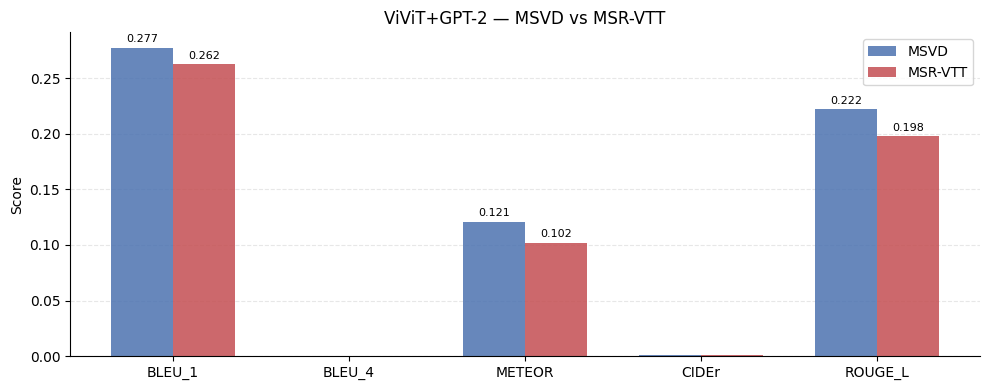

In [18]:
import matplotlib.pyplot as plt, numpy as np, os, json

_metrics = ['BLEU_1','BLEU_4','METEOR','CIDEr','ROUGE_L']
_colors  = ['#4C72B0','#C44E52']
_fig, _ax = plt.subplots(figsize=(10, 4))
_x = np.arange(len(_metrics)); _w = 0.35

# Load scores
scores_vg2_msvd = {}
scores_vg2_msrvtt = {}
msvd_scores_path = os.path.join(RESULTS_DIR, 'ViViT_plus_GPT_2_MSVD_scores.json')
msrvtt_scores_path = os.path.join(RESULTS_DIR, 'ViViT_plus_GPT_2_MSR-VTT_scores.json')

if os.path.exists(msvd_scores_path):
    with open(msvd_scores_path, 'r') as f:
        scores_vg2_msvd = json.load(f)
else:
    print(f"Warning: MSVD scores file not found at {msvd_scores_path}")

if os.path.exists(msrvtt_scores_path):
    with open(msrvtt_scores_path, 'r') as f:
        scores_vg2_msrvtt = json.load(f)
else:
    print(f"Warning: MSR-VTT scores file not found at {msrvtt_scores_path}")

for _j, (_ds, _sc, _col) in enumerate([
        ('MSVD',    scores_vg2_msvd,   '#4C72B0'),
        ('MSR-VTT', scores_vg2_msrvtt,  '#C44E52')]):
    _vals = [_sc['scores'][m] for m in _metrics]
    _bars = _ax.bar(_x+(_j-0.5)*_w, _vals, _w, label=_ds, color=_col, alpha=0.85)
    for _b,_v in zip(_bars,_vals):
        if _v>0.005: _ax.text(_b.get_x()+_b.get_width()/2, _b.get_height()+0.003,
                              f'{_v:.3f}',ha='center',va='bottom',fontsize=8)
_ax.set_xticks(_x); _ax.set_xticklabels(_metrics, fontsize=10)
_ax.set_ylabel('Score', fontsize=10)
_ax.set_title('ViViT+GPT-2 — MSVD vs MSR-VTT', fontsize=12)
_ax.legend(fontsize=10)
_ax.spines[['top','right']].set_visible(False)
_ax.yaxis.grid(True, alpha=0.3, linestyle='--'); _ax.set_axisbelow(True)
plt.tight_layout()
_fig_path = os.path.join(RESULTS_DIR,'vg2_inline_chart.png')
plt.savefig(_fig_path, dpi=150, bbox_inches='tight')
plt.show()

# Ensure MLFLOW_ACTIVE is defined even if the setup cell failed
if 'MLFLOW_ACTIVE' not in globals():
    MLFLOW_ACTIVE = False

if MLFLOW_ACTIVE:
    with start_run_ctx('ViViT+GPT-2','Both'):
        log_eval_results({'scores':scores_vg2_msvd,'hypotheses':{},'references':{},'timing':{}},                          'ViViT+GPT-2','MSVD')
        log_eval_results({'scores':scores_vg2_msrvtt,'hypotheses':{},'references':{},'timing':{}},                          'ViViT+GPT-2','MSR-VTT')
        log_figure(_fig_path)
    print_run_url()


In [20]:
import glob
print("\n── Member A: all saved artifacts ──────────────────────")
for f in sorted(glob.glob(os.path.join(RESULTS_DIR,"CLIP_plus*"))+
                glob.glob(os.path.join(RESULTS_DIR,"ViViT*"))):
    print(f"  {os.path.basename(f):<55} {os.path.getsize(f):>8,} B")



── Member A: all saved artifacts ──────────────────────
  CLIP_plus_GPT_2_MSR-VTT_ablation_frames.json               6,383 B
  CLIP_plus_GPT_2_MSR-VTT_examples.csv                      14,466 B
  CLIP_plus_GPT_2_MSR-VTT_hypotheses.json                   10,302 B
  CLIP_plus_GPT_2_MSR-VTT_per_video_scores.csv               3,861 B
  CLIP_plus_GPT_2_MSR-VTT_references.json                  113,421 B
  CLIP_plus_GPT_2_MSR-VTT_scores.json                          176 B
  CLIP_plus_GPT_2_MSR-VTT_timing.json                        1,322 B
  CLIP_plus_GPT_2_MSVD_ablation_frames.json                  6,383 B
  CLIP_plus_GPT_2_MSVD_examples.csv                         17,919 B
  CLIP_plus_GPT_2_MSVD_hypotheses.json                      11,119 B
  CLIP_plus_GPT_2_MSVD_per_video_scores.csv                  4,675 B
  CLIP_plus_GPT_2_MSVD_references.json                     471,925 B
  CLIP_plus_GPT_2_MSVD_scores.json                             172 B
  CLIP_plus_GPT_2_MSVD_timing.json            